## Experiment 5 — Weight Decay

### Objective

In this experiment, we investigate whether **Weight Decay** can reduce overfitting by limiting the magnitude of the model's weights and improving its performance on the validation set.

We compare two settings:

* `weight_decay = 0`
* `weight_decay = 1e-4`

All other conditions, including the **model architecture, train/validation split, random seed, learning rate, batch size, number of epochs, and transforms**, are kept constant.

The **validation set** is used only to compare the two models, and the **test set is not used** in this experiment.


In [36]:
import sys
from pathlib import Path
from torchvision import datasets
import numpy as np
import torch
import torch.nn as nn
import matplotlib.pyplot as plt
import math
from collections import Counter
import json

from torch.optim import Adam
from torchvision import transforms

from sklearn.metrics import classification_report

# Project root
PROJECT_DIR = Path.cwd().parent

if str(PROJECT_DIR) not in sys.path:
    sys.path.insert(0, str(PROJECT_DIR))

sys.path.append("../src")

from data import (
    letterbox,
    create_train_val_datasets,
    create_dataloaders
)

from models import SimpleCNN

from train import train_model

from utils import (
    get_predictions,
    plot_confusion_matrix,
    get_classification_report,
    plot_training_history,
    set_seed
)

### Configuration

In [2]:
SEED = 42
set_seed(SEED)
BATCH_SIZE = 32
EPOCHS = 10
LEARNING_RATE = 1e-3
NUM_CLASSES = 8



DEVICE = torch.device(
    "cuda" if torch.cuda.is_available() else "cpu"
)

print("Device:", DEVICE)

Device: cpu


### Paths

In [39]:
MERGED_TRAIN_DIR = PROJECT_DIR / "dataset" / "merged_train"


print("Training directory:", MERGED_TRAIN_DIR)


print("Training directory exists:", MERGED_TRAIN_DIR.exists())

Training directory: d:\AI Bootcamp_M Sharif\traffic_vehicle_project\dataset\merged_train
Training directory exists: True


### Transforms as the Baseline Model

In [4]:
baseline_transform = transforms.Compose([
    transforms.Lambda(
        lambda img: letterbox(
            img,
            target_size=(224, 224)
        )
    ),
    transforms.ToTensor(),
    transforms.Normalize(
        mean=[0.485, 0.456, 0.406],
        std=[0.229, 0.224, 0.225]
    )
])

### Create Train/Validation Dataset

In [6]:
train_dataset, val_dataset, train_indices, val_indices,class_to_idx= \
    create_train_val_datasets(
        data_dir=MERGED_TRAIN_DIR,
        train_transform=baseline_transform,
        val_transform=baseline_transform,
        test_size=0.2,
        seed=SEED
    )

### Class Names and Dataset Size

In [7]:
full_dataset = datasets.ImageFolder(
    MERGED_TRAIN_DIR
)

class_names = full_dataset.classes
class_to_idx = full_dataset.class_to_idx

print("Classes:")
for index, class_name in enumerate(class_names):
    print(index, "->", class_name)

print("\nNumber of classes:", len(class_names))


train_class_counts = Counter(
    full_dataset.targets[i]
    for i in train_indices
)

val_class_counts = Counter(
    full_dataset.targets[i]
    for i in val_indices
)

print("Class distribution:")
print()

for class_index, class_name in enumerate(class_names):
    train_count = train_class_counts[class_index]
    val_count = val_class_counts[class_index]

    print(
        f"{class_index} -> {class_name}: "
        f"Train = {train_count} ({train_count / len(train_dataset):.1%}), "
        f"Validation = {val_count} ({val_count / len(val_dataset):.1%})"
    )

print("Total training samples:", len(train_dataset) + len(val_dataset))
print("Training samples:", len(train_dataset))
print("Validation samples:", len(val_dataset))

Classes:
0 -> ambulance
1 -> autobus
2 -> kamyun
3 -> kamyunet
4 -> minibus
5 -> savari
6 -> taxi
7 -> vanet

Number of classes: 8
Class distribution:

0 -> ambulance: Train = 289 (10.7%), Validation = 73 (10.8%)
1 -> autobus: Train = 376 (13.9%), Validation = 94 (13.8%)
2 -> kamyun: Train = 397 (14.6%), Validation = 99 (14.6%)
3 -> kamyunet: Train = 364 (13.4%), Validation = 91 (13.4%)
4 -> minibus: Train = 329 (12.1%), Validation = 82 (12.1%)
5 -> savari: Train = 400 (14.7%), Validation = 100 (14.7%)
6 -> taxi: Train = 394 (14.5%), Validation = 99 (14.6%)
7 -> vanet: Train = 164 (6.0%), Validation = 41 (6.0%)
Total training samples: 3392
Training samples: 2713
Validation samples: 679


### Data Loaders

In [8]:
train_loader, val_loader = create_dataloaders(
    train_dataset=train_dataset,
    val_dataset=val_dataset,
    batch_size=BATCH_SIZE,
    shuffle_train=True
)

print("Number of training batches:", len(train_loader))
print("Number of validation batches:", len(val_loader))

Number of training batches: 85
Number of validation batches: 22


### Checking one Batch

Images shape: torch.Size([32, 3, 224, 224])
Labels shape: torch.Size([32])
Labels: tensor([1, 0, 0, 3, 6, 4, 1, 0, 3, 2, 2, 6, 6, 2, 2, 5, 4, 5, 1, 6, 5, 0, 0, 3,
        2, 3, 6, 5, 2, 0, 2, 4])


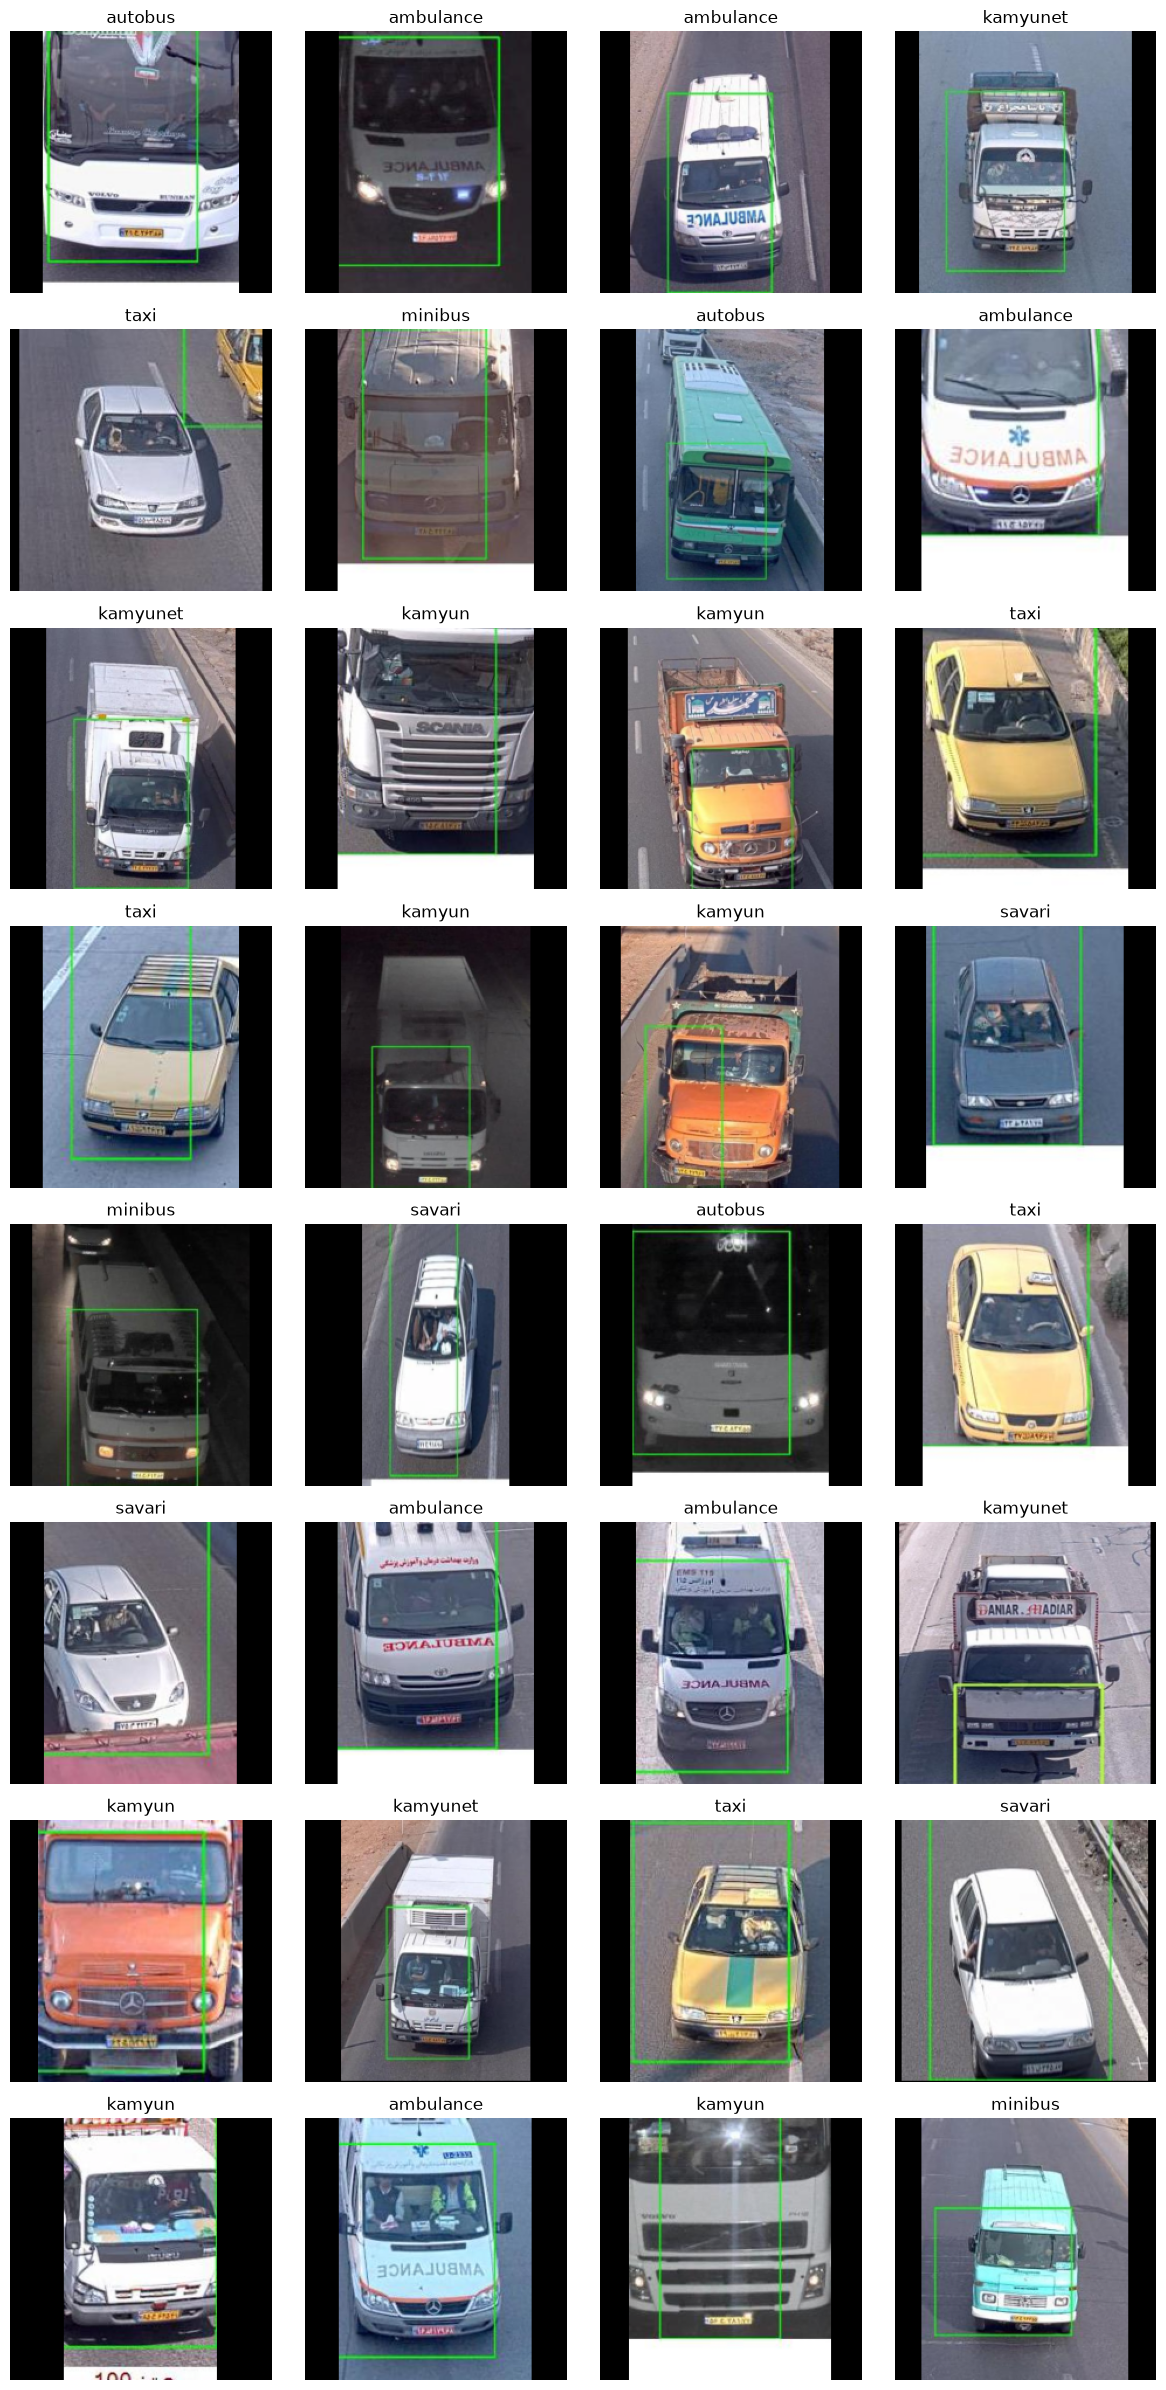

In [9]:
images, labels = next(iter(train_loader))

print("Images shape:", images.shape)
print("Labels shape:", labels.shape)
print("Labels:", labels)

# ImageNet normalization values
mean = torch.tensor([0.485, 0.456, 0.406]).view(3, 1, 1)
std = torch.tensor([0.229, 0.224, 0.225]).view(3, 1, 1)

num_images = len(images)
cols = 4
rows = math.ceil(num_images / cols)

plt.figure(figsize=(12, 3 * rows))

for i in range(num_images):
    # Denormalize
    image = images[i] * std + mean

    # CHW -> HWC
    image = image.permute(1, 2, 0)

    # Keep values in valid display range
    image = image.clamp(0, 1)

    plt.subplot(rows, cols, i + 1)
    plt.imshow(image)
    plt.title(class_names[labels[i].item()])
    plt.axis("off")

plt.tight_layout()
plt.show()

### The Same Model as the Baseline Model

In [10]:
model = SimpleCNN(
    num_classes=NUM_CLASSES,
    dropout=0.0,
    use_gap=False
)

model = model.to(DEVICE)

print(model)

SimpleCNN(
  (features): Sequential(
    (0): Conv2d(3, 32, kernel_size=(3, 3), stride=(1, 1), padding=(1, 1))
    (1): ReLU()
    (2): MaxPool2d(kernel_size=2, stride=2, padding=0, dilation=1, ceil_mode=False)
    (3): Conv2d(32, 64, kernel_size=(3, 3), stride=(1, 1), padding=(1, 1))
    (4): ReLU()
    (5): MaxPool2d(kernel_size=2, stride=2, padding=0, dilation=1, ceil_mode=False)
  )
  (pool): Identity()
  (classifier): Sequential(
    (0): Flatten(start_dim=1, end_dim=-1)
    (1): Linear(in_features=200704, out_features=128, bias=True)
    (2): ReLU()
    (3): Dropout(p=0.0, inplace=False)
    (4): Linear(in_features=128, out_features=8, bias=True)
  )
)


## Controlled comparison

The only variable that changes between the two models is `weight_decay`.

The architecture, dropout, pooling, learning rate, optimizer type,
batch size, number of epochs, seed, train/validation split, and
transforms remain constant.

### Criterion

In [11]:
criterion = nn.CrossEntropyLoss()

### Train Weight Decay

In [12]:
model_wd0 = SimpleCNN(
    num_classes=NUM_CLASSES,
    dropout=0.0,
    use_gap=False
).to(DEVICE)

optimizer_wd0 = torch.optim.AdamW(
    model_wd0.parameters(),
    lr=LEARNING_RATE,
    weight_decay=0.0
)

In [13]:
history_wd0, best_val_acc_wd0 = train_model(
    model=model_wd0,
    train_loader=train_loader,
    val_loader=val_loader,
    criterion=criterion,
    optimizer=optimizer_wd0,
    device=DEVICE,
    epochs=EPOCHS,
    model_name="weight_decay_0",
    class_to_idx=class_to_idx,
    seed=SEED,
    config={
    "model" : "SimpleCNN",
    "experiment": "weight_decay",
    "weight_decay": 0,
    "optimizer": "AdamW",  
    "num_classes": NUM_CLASSES,
    "dropout": 0.0,
    "use_gap": False,
    "batch_size": BATCH_SIZE,
    "learning_rate": LEARNING_RATE,
    "epochs": EPOCHS,
    "train_transform": [
        "LetterBox",
        "Resize(224,224)",
        "ToTensor",
        "Normalize"
    ],

    "val_transform": [
        "LetterBox",
        "Resize(224,224)",
        "ToTensor",
        "Normalize"
    ]
}
)

Epoch [1/10] Train Loss: 2.5685 --- Train Acc: 0.2820 --- Val Loss: 1.5429 --- Val Acc: 0.4138
Epoch [2/10] Train Loss: 1.1581 --- Train Acc: 0.5886 --- Val Loss: 1.2461 --- Val Acc: 0.6156
Epoch [3/10] Train Loss: 0.5615 --- Train Acc: 0.8131 --- Val Loss: 0.8116 --- Val Acc: 0.7320
Epoch [4/10] Train Loss: 0.2450 --- Train Acc: 0.9244 --- Val Loss: 0.8887 --- Val Acc: 0.7290
Epoch [5/10] Train Loss: 0.0944 --- Train Acc: 0.9760 --- Val Loss: 1.0462 --- Val Acc: 0.7467
Epoch [6/10] Train Loss: 0.0426 --- Train Acc: 0.9878 --- Val Loss: 1.1573 --- Val Acc: 0.7555
Epoch [7/10] Train Loss: 0.0146 --- Train Acc: 0.9971 --- Val Loss: 1.2361 --- Val Acc: 0.7541
Epoch [8/10] Train Loss: 0.0023 --- Train Acc: 1.0000 --- Val Loss: 1.2594 --- Val Acc: 0.7555
Epoch [9/10] Train Loss: 0.0013 --- Train Acc: 1.0000 --- Val Loss: 1.3124 --- Val Acc: 0.7585
Epoch [10/10] Train Loss: 0.0008 --- Train Acc: 1.0000 --- Val Loss: 1.3452 --- Val Acc: 0.7614

Best checkpoint saved:
D:\AI Bootcamp_M Sharif\t

## Run 2 — Weight Decay = 1e-4

In this run, only the weight decay is modified.

The goal is to examine the effect of adding regularization
on training and validation behavior.

In [14]:
model_wd1e4 = SimpleCNN(
    num_classes=NUM_CLASSES,
    dropout=0.0,
    use_gap=False
).to(DEVICE)

optimizer_wd1e4 = torch.optim.AdamW(
    model_wd1e4.parameters(),
    lr=LEARNING_RATE,
    weight_decay=1e-4
)



In [15]:
history_wd1e4, best_val_acc_wd1e4 = train_model(
    model=model_wd1e4,
    train_loader=train_loader,
    val_loader=val_loader,
    criterion=criterion,
    optimizer=optimizer_wd1e4,
    device=DEVICE,
    epochs=EPOCHS,
    model_name="weight_decay_1e4",
    class_to_idx=class_to_idx,
    seed=SEED,
    config={
    "model" : "SimpleCNN",
    "experiment": "weight_decay",
    "weight_decay": 1e-4,
    "optimizer": "AdamW",  
    "num_classes": NUM_CLASSES,
    "dropout": 0.0,
    "use_gap": False,
    "batch_size": BATCH_SIZE,
    "learning_rate": LEARNING_RATE,
    "epochs": EPOCHS,
    "train_transform": [
        "LetterBox",
        "Resize(224,224)",
        "ToTensor",
        "Normalize"
    ],

    "val_transform": [
        "LetterBox",
        "Resize(224,224)",
        "ToTensor",
        "Normalize"
    ]
}
)

Epoch [1/10] Train Loss: 2.6121 --- Train Acc: 0.3645 --- Val Loss: 1.2484 --- Val Acc: 0.5493
Epoch [2/10] Train Loss: 0.9505 --- Train Acc: 0.6683 --- Val Loss: 0.9519 --- Val Acc: 0.6819
Epoch [3/10] Train Loss: 0.6083 --- Train Acc: 0.7836 --- Val Loss: 0.8660 --- Val Acc: 0.6996
Epoch [4/10] Train Loss: 0.3677 --- Train Acc: 0.8699 --- Val Loss: 0.8549 --- Val Acc: 0.7555
Epoch [5/10] Train Loss: 0.2358 --- Train Acc: 0.9289 --- Val Loss: 0.8975 --- Val Acc: 0.7747
Epoch [6/10] Train Loss: 0.1192 --- Train Acc: 0.9602 --- Val Loss: 0.9678 --- Val Acc: 0.7541
Epoch [7/10] Train Loss: 0.0461 --- Train Acc: 0.9900 --- Val Loss: 1.0528 --- Val Acc: 0.7673
Epoch [8/10] Train Loss: 0.0189 --- Train Acc: 0.9963 --- Val Loss: 1.0758 --- Val Acc: 0.7791
Epoch [9/10] Train Loss: 0.0062 --- Train Acc: 1.0000 --- Val Loss: 1.0849 --- Val Acc: 0.7806
Epoch [10/10] Train Loss: 0.0021 --- Train Acc: 1.0000 --- Val Loss: 1.1418 --- Val Acc: 0.7820

Best checkpoint saved:
D:\AI Bootcamp_M Sharif\t

### Training Curves - Weight Decay = 00

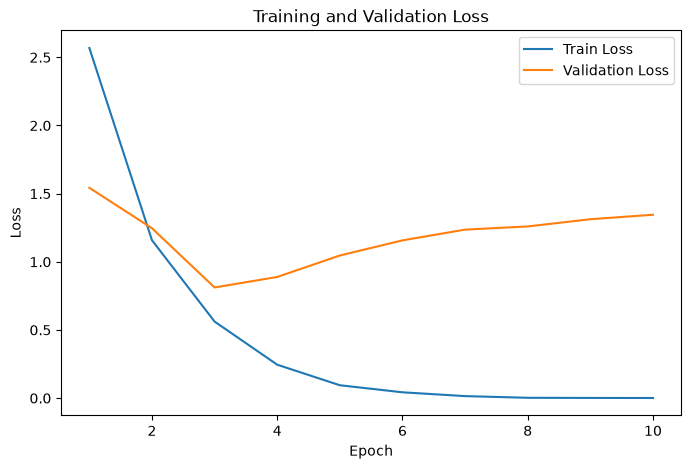

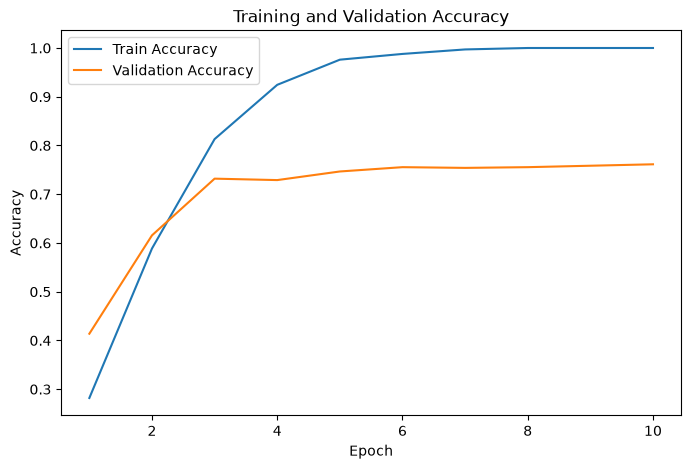

In [16]:
plot_training_history(history=history_wd0)

### Training Curves - Weight Decay = 1e-4 

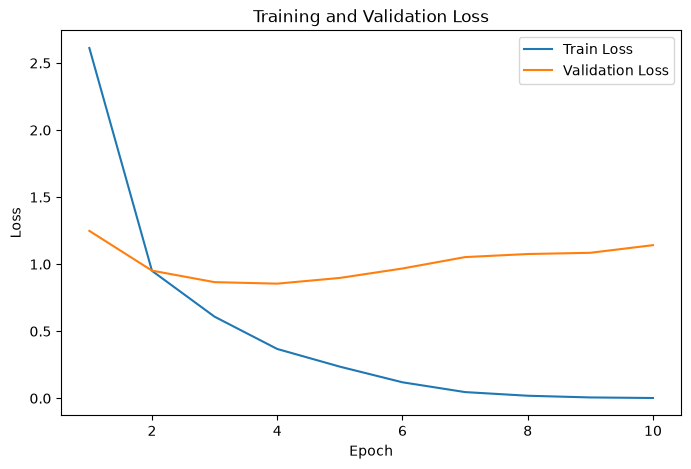

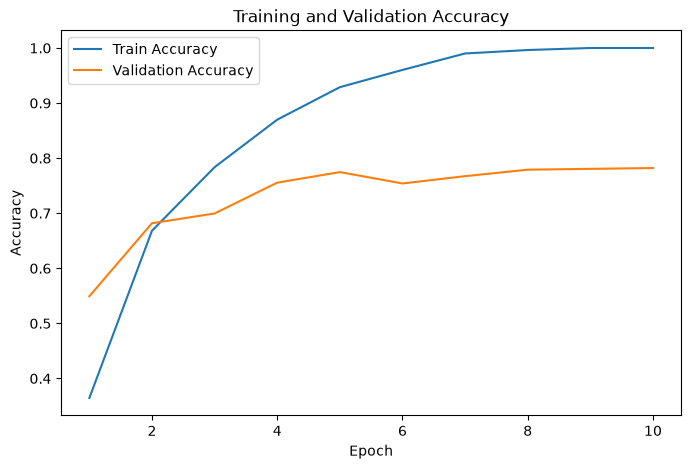

In [17]:
plot_training_history(history=history_wd1e4)

### Best Epoch For Each Of Them

In [20]:
print("Weigh Decay = 0")
best_epoch_wd0 = np.argmax(
    history_wd0["val_accuracy"]
) + 1

print("Best epoch:", best_epoch_wd0)
print("Best validation accuracy:", best_val_acc_wd0)

print ("*"*30)
print("1e4")
best_epoch_wd1e4 = np.argmax(
    history_wd1e4["val_accuracy"]
) + 1

print("Best epoch:", best_epoch_wd1e4)
print("Best validation accuracy:", best_val_acc_wd1e4)

Weigh Decay = 0
Best epoch: 10
Best validation accuracy: 0.7614138438880707
******************************
1e4
Best epoch: 10
Best validation accuracy: 0.7820324005891016


## Train/Validation Gap

In [38]:
wd0_best_epoch = np.argmax(
    history_wd0["val_accuracy"]
)

wd0_best_train_accuracy = history_wd0["train_accuracy"][wd0_best_epoch]
wd0_best_val_accuracy = history_wd0["val_accuracy"][wd0_best_epoch]
wd0_gap = wd0_best_train_accuracy - wd0_best_val_accuracy

print("wd0 Best Epoch:", wd0_best_epoch + 1)

print(
    "wd0 Best Train Accuracy:",
    wd0_best_train_accuracy
)

print(
    "wd0 Best Validation Accuracy:",
    wd0_best_val_accuracy
)

print(
    "wd0 Train-Validation Gap:",
    wd0_gap
)

print ("*"*30)

wd1e4_best_epoch = np.argmax(
    history_wd1e4["val_accuracy"]
)

wd1e4_best_train_accuracy = history_wd1e4["train_accuracy"][wd1e4_best_epoch]
wd1e4_best_val_accuracy = history_wd1e4["val_accuracy"][wd1e4_best_epoch]
wd1e4_gap = wd1e4_best_train_accuracy - wd1e4_best_val_accuracy
print("wd1e4 Best Epoch:", wd1e4_best_epoch + 1)

print(
    "wd1e4 Best Train Accuracy:",
    wd1e4_best_train_accuracy
)

print(
    "wd1e4 Best Validation Accuracy:",
    wd1e4_best_val_accuracy
)

print(
    "wd1e4 Train-Validation Gap:",
    wd1e4_gap
)

wd0 Best Epoch: 10
wd0 Best Train Accuracy: 1.0
wd0 Best Validation Accuracy: 0.7614138438880707
wd0 Train-Validation Gap: 0.23858615611192935
******************************
wd1e4 Best Epoch: 10
wd1e4 Best Train Accuracy: 1.0
wd1e4 Best Validation Accuracy: 0.7820324005891016
wd1e4 Train-Validation Gap: 0.21796759941089838


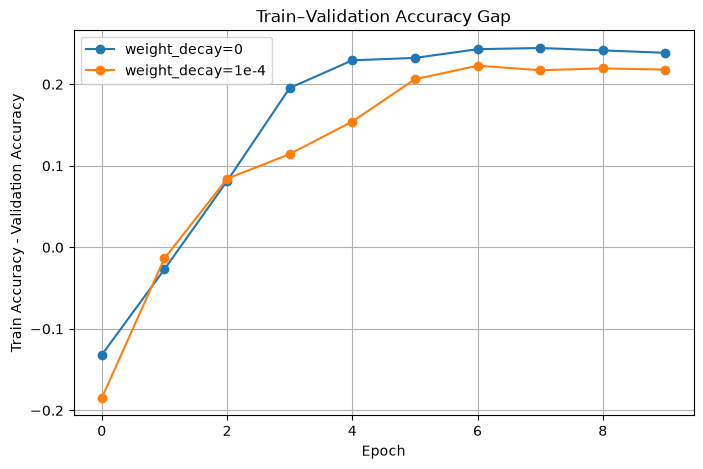

In [26]:
wd0_gap = [
    train_acc - val_acc
    for train_acc, val_acc in zip(
        history_wd0["train_accuracy"],
        history_wd0["val_accuracy"]
    )
]

wd1e4_gap = [
    train_acc - val_acc
    for train_acc, val_acc in zip(
        history_wd1e4["train_accuracy"],
        history_wd1e4["val_accuracy"]
    )
]


plt.figure(figsize=(8, 5))

plt.plot(
    wd0_gap,
    marker="o",
    label="weight_decay=0"
)

plt.plot(
    wd1e4_gap,
    marker="o",
    label="weight_decay=1e-4"
)

plt.xlabel("Epoch")
plt.ylabel("Train Accuracy - Validation Accuracy")
plt.title("Train–Validation Accuracy Gap")
plt.legend()
plt.grid()
plt.show()

### Load Best Checkpoint for Weight Decay = 0

In [27]:
# =========================
# Weight Decay = 0
# =========================

wd0_checkpoint_path = (
    PROJECT_DIR
    / "checkpoints"
    / "weight_decay_0_best.pt"
)

wd0_checkpoint = torch.load(
    wd0_checkpoint_path,
    map_location=DEVICE
)

model.load_state_dict(
    wd0_checkpoint["model_state_dict"]
)

print("Best Weight Decay 0 epoch:", wd0_checkpoint["epoch"])
print(
    "Best Weight Decay 0 validation accuracy:",
    wd0_checkpoint["val_accuracy"]
)


Best Weight Decay 0 epoch: 10
Best Weight Decay 0 validation accuracy: 0.7614138438880707


### Validation Prediction for Weight Decay 0 

In [28]:
true_labels_wd0, predictions_wd0 = get_predictions(
    model=model,
    loader=val_loader,
    device=DEVICE
)

correct_wd0 = (true_labels_wd0 == predictions_wd0).sum()
accuracy_wd0 = correct_wd0 / len(predictions_wd0)

print("Number of validation predictions:", len(predictions_wd0))
print("Number of correct predictions:", correct_wd0)
print("Validation accuracy:", accuracy_wd0)

Number of validation predictions: 679
Number of correct predictions: 517
Validation accuracy: 0.7614138438880707


### Classification Report,Confusion Matrix and Normalized Comfusion Matrix for Weight Decay 0

Weight Decay = 0
              precision    recall  f1-score   support

   ambulance     0.8308    0.7397    0.7826        73
     autobus     0.8710    0.8617    0.8663        94
      kamyun     0.5856    0.6566    0.6190        99
    kamyunet     0.6444    0.6374    0.6409        91
     minibus     0.7857    0.8049    0.7952        82
      savari     0.7672    0.8900    0.8241       100
        taxi     0.9468    0.8990    0.9223        99
       vanet     0.5769    0.3659    0.4478        41

    accuracy                         0.7614       679
   macro avg     0.7511    0.7319    0.7373       679
weighted avg     0.7624    0.7614    0.7591       679

******************************


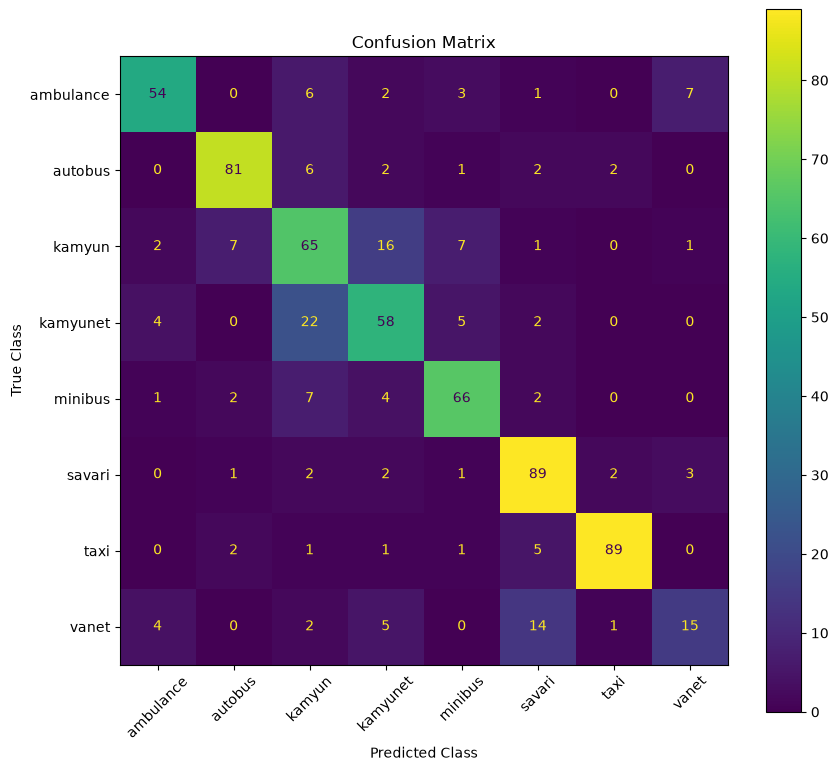

******************************


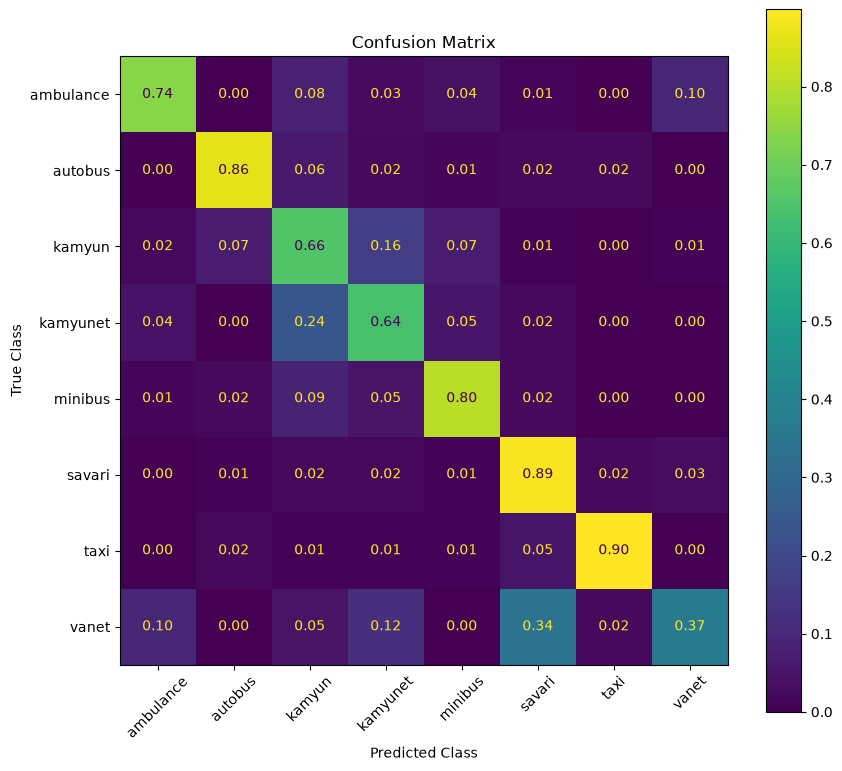

In [29]:
print ("Weight Decay = 0")
report_wd0 = get_classification_report(
    model=model,
    loader=val_loader,
    class_names=class_names,
    device=DEVICE
)

print ("*"*30)

cm_wd0 = plot_confusion_matrix(
    model=model,
    loader=val_loader,
    class_names=class_names,
    device=DEVICE
)

print ("*"*30)

cm_normalized_wd0 = plot_confusion_matrix(
    model=model,
    loader=val_loader,
    class_names=class_names,
    device=DEVICE,
    normalize="true"
)

### Load Best Checkpoint for Weight Decay = 1e4

In [30]:
# =========================
# Weight Decay = 1e4
# =========================

wd1e4_checkpoint_path = (
    PROJECT_DIR
    / "checkpoints"
    / "weight_decay_1e4_best.pt"
)

wd1e4_checkpoint = torch.load(
    wd1e4_checkpoint_path,
    map_location=DEVICE
)

model.load_state_dict(
    wd1e4_checkpoint["model_state_dict"]
)

print("Best Weight Decay 1e4 epoch:", wd1e4_checkpoint["epoch"])
print(
    "Best Weight Decay 1e4 validation accuracy:",
    wd1e4_checkpoint["val_accuracy"]
)

Best Weight Decay 1e4 epoch: 10
Best Weight Decay 1e4 validation accuracy: 0.7820324005891016


### Validation Prediction for Weight Decay 1e4

In [31]:
true_labels_wd1e4, predictions_wd1e4 = get_predictions(
    model=model,
    loader=val_loader,
    device=DEVICE
)

correct_wd1e4 = (true_labels_wd1e4 == predictions_wd1e4).sum()
accuracy_wd1e4 = correct_wd1e4 / len(predictions_wd1e4)

print("Number of validation predictions:", len(predictions_wd1e4))
print("Number of correct predictions:", correct_wd1e4)
print("Validation accuracy:", accuracy_wd1e4)


Number of validation predictions: 679
Number of correct predictions: 531
Validation accuracy: 0.7820324005891016


### Classification Report,Confusion Matrix and Normalized Comfusion Matrix for Weight Decay 1e4

Weight Decay = 1e4
              precision    recall  f1-score   support

   ambulance     0.8028    0.7808    0.7917        73
     autobus     0.8750    0.8936    0.8842        94
      kamyun     0.6250    0.6566    0.6404        99
    kamyunet     0.6706    0.6264    0.6477        91
     minibus     0.8049    0.8049    0.8049        82
      savari     0.8286    0.8700    0.8488       100
        taxi     0.9495    0.9495    0.9495        99
       vanet     0.5676    0.5122    0.5385        41

    accuracy                         0.7820       679
   macro avg     0.7655    0.7617    0.7632       679
weighted avg     0.7804    0.7820    0.7809       679

******************************


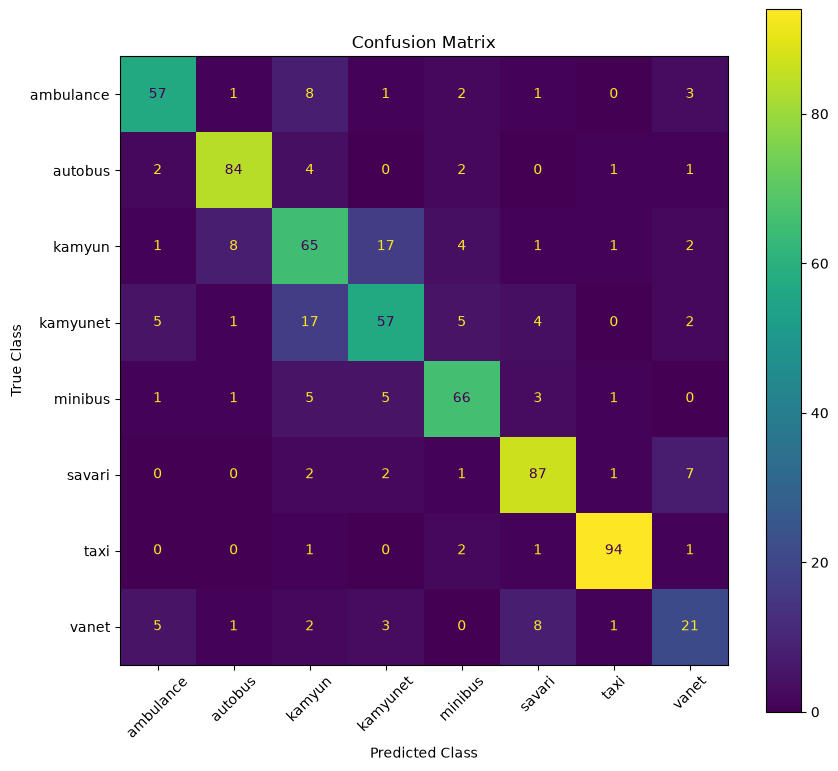

******************************


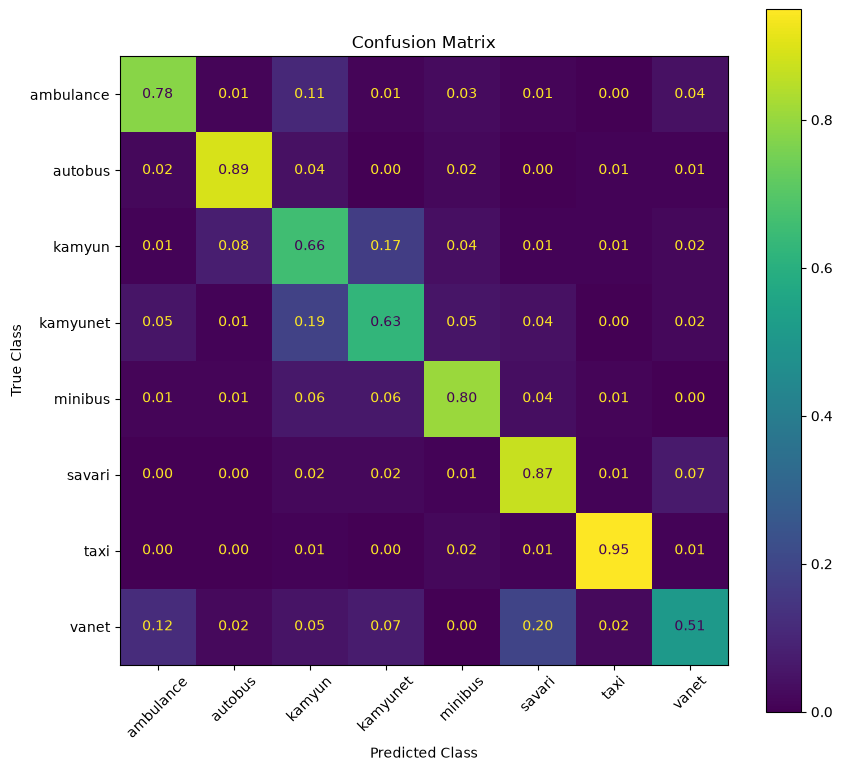

In [32]:
print ("Weight Decay = 1e4")
report_wd1e4 = get_classification_report(
    model=model,
    loader=val_loader,
    class_names=class_names,
    device=DEVICE
)

print ("*"*30)

cm_wd1e4 = plot_confusion_matrix(
    model=model,
    loader=val_loader,
    class_names=class_names,
    device=DEVICE
)

print ("*"*30)

cm_normalized_wd1e4 = plot_confusion_matrix(
    model=model,
    loader=val_loader,
    class_names=class_names,
    device=DEVICE,
    normalize="true"
)

### Weight Decay 0,1e4 Final Results

In [33]:
from sklearn.metrics import (
    accuracy_score,
    precision_score,
    recall_score,
    f1_score
)

wd0_accuracy = accuracy_score(
    true_labels_wd0,
    predictions_wd0
)

wd0_precision = precision_score(
    true_labels_wd0,
    predictions_wd0,
    average="macro",
    zero_division=0
)

wd0_recall = recall_score(
    true_labels_wd0,
    predictions_wd0,
    average="macro",
    zero_division=0
)

wd0_f1 = f1_score(
    true_labels_wd0,
    predictions_wd0,
    average="macro",
    zero_division=0
)

print("WD 0 Validation Results")
print("---------------------------")
print("Accuracy:", wd0_accuracy)
print("Macro Precision:", wd0_precision)
print("Macro Recall:", wd0_recall)
print("Macro F1:", wd0_f1)

WD 0 Validation Results
---------------------------
Accuracy: 0.7614138438880707
Macro Precision: 0.7510567819150937
Macro Recall: 0.7318847569115126
Macro F1: 0.7372682795962198


In [34]:
wd1e4_accuracy = accuracy_score(
    true_labels_wd1e4,
    predictions_wd1e4
)

wd1e4_precision = precision_score(
    true_labels_wd1e4,
    predictions_wd1e4,
    average="macro",
    zero_division=0
)

wd1e4_recall = recall_score(
    true_labels_wd1e4,
    predictions_wd1e4,
    average="macro",
    zero_division=0
)

wd1e4_f1 = f1_score(
    true_labels_wd1e4,
    predictions_wd1e4,
    average="macro",
    zero_division=0
)

print("WD 1e4 Validation Results")
print("---------------------------")
print("Accuracy:", wd1e4_accuracy)
print("Macro Precision:", wd1e4_precision)
print("Macro Recall:", wd1e4_recall)
print("Macro F1:", wd1e4_f1)

WD 1e4 Validation Results
---------------------------
Accuracy: 0.7820324005891016
Macro Precision: 0.7654896413896252
Macro Recall: 0.7617432927813443
Macro F1: 0.7632016973651916


### Final Comparision Weight Decay 0 , Weight Decay 1e4 and Baseline Model

In [37]:
RESULTS_FILE = PROJECT_DIR / "results" / "experiment_results.json"

with open(RESULTS_FILE, "r", encoding="utf-8") as f:
    results = json.load(f)
    
# Baseline Model
baseline_result = results["baseline_cnn"]

print("Baseline Results")
print("----------------")
print("Best Epoch:", baseline_result["best_epoch"])
print("Best Validation Accuracy:", baseline_result["best_val_accuracy"])
print("Validation Loss at Best Epoch:", baseline_result["best_val_loss"])
print("*" * 30)

wd0_result = results["weight_decay_0"]

print("WD 0  Results")
print("----------------")
print("Best Epoch:", wd0_result["best_epoch"])
print("Best Validation Accuracy:", wd0_result["best_val_accuracy"])
print("Validation Loss at Best Epoch:", wd0_result["best_val_loss"])
print("*" * 30)

wd1e4_result = results["weight_decay_1e4"]

print("WD 1e4  Results")
print("----------------")
print("Best Epoch:", wd1e4_result["best_epoch"])
print("Best Validation Accuracy:", wd1e4_result["best_val_accuracy"])
print("Validation Loss at Best Epoch:", wd1e4_result["best_val_loss"])
print("*" * 30)



Baseline Results
----------------
Best Epoch: 9
Best Validation Accuracy: 0.7893961708394698
Validation Loss at Best Epoch: 1.1164248662072183
******************************
WD 0  Results
----------------
Best Epoch: 10
Best Validation Accuracy: 0.7614138438880707
Validation Loss at Best Epoch: 1.3451686284679025
******************************
WD 1e4  Results
----------------
Best Epoch: 10
Best Validation Accuracy: 0.7820324005891016
Validation Loss at Best Epoch: 1.1418304064136893
******************************
